In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd

In [2]:
adata = ad.read_h5ad("/dcs04/lieber/lcolladotor/spatialDLPFC_LIBD4035/spatialDLPFC/raw-data/psychENCODE/version5/SZBDMulti-Seq_annotated.h5ad")

In [3]:
adata.obs.columns

Index(['n_genes', 'n_counts', 'Channel', 'demux_type', 'assignment', 'anno',
       'subclass', 'azimuth', 'individualID'],
      dtype='object')

In [21]:
adata.obs.groupby(['individualID'], observed=True).size()

individualID
BD1      1692
BD2      3648
BD3      1093
BD4     18585
BD5      2645
        ...  
SZ20     8108
SZ21     6378
SZ22     2948
SZ23     6476
SZ24     5519
Length: 72, dtype: int64

In [3]:
mdata = pd.read_csv('https://brainscope.gersteinlab.org/data/sample_metadata/PEC2_sample_metadata.txt', delimiter='\t')
mdata = mdata[mdata.Cohort=='SZBDMulti-Seq']

In [9]:
mdata.columns

Index(['Cohort', 'Individual_ID', 'Biological_Sex', 'Age_death', 'Disorder',
       '1000G_ancestry', 'Genotype_data', 'snATAC-Seq', 'PMI', 'pH', 'RIN',
       'Notes'],
      dtype='object')

In [4]:
#rename mdata column for easier merge with adata obs
mdata = mdata.rename(columns={"Individual_ID":"individualID"})

In [5]:
# first is to store index as column
# then merge with mdata based on individualID which is set as new index
# then reset index and store the whole thing as a copy not as view
adata.obs = adata.obs.reset_index().merge(mdata[mdata.columns[1:5]], on="individualID", how="left").set_index('barcodekey').copy()

In [6]:
adata

AnnData object with n_obs × n_vars = 484136 × 34291
    obs: 'n_genes', 'n_counts', 'Channel', 'demux_type', 'assignment', 'anno', 'subclass', 'azimuth', 'individualID', 'Biological_Sex', 'Age_death', 'Disorder'
    var: 'featureid', 'n_cells', 'percent_cells'
    uns: 'PCs', '_attr2type', 'genome', 'leiden_resolution', 'modality', 'ncells', 'norm_count', 'pca', 'pca_features', 'stdzn_max_value', 'stdzn_mean', 'stdzn_std', 'uns_dict', 'var_dict'
    obsm: 'X_pca', 'X_pca_harmony', 'X_pca_regressed', 'X_pca_regressed_harmony', 'X_umap', 'pca_harmony_knn_distances', 'pca_harmony_knn_indices', 'pca_regressed_harmony_knn_distances', 'pca_regressed_harmony_knn_indices'
    varm: 'de_res', 'means', 'partial_sum'
    obsp: 'W_pca_harmony', 'W_pca_regressed_harmony'

In [35]:
adata.obs

,n_genes,n_counts,Channel,demux_type,assignment,anno,subclass,azimuth,individualID,Biological_Sex,Age_death,Disorder
barcodekey,,,,,,,,,,,,
D19-4295_BD1-TTCCTGCC-D19-4295-AACCATGAGTCACTCA,4830,16425,D19-4295_BD1-TTCCTGCC-D19-4295-,singlet,BD1-TTCCTGCC,L2/3 IT-3,L2/3 IT,L2/3 IT,BD1,female,73,Bipolar Disorder
D19-4295_BD1-TTCCTGCC-D19-4295-GAATCGTAGTAGGTTA,4535,14069,D19-4295_BD1-TTCCTGCC-D19-4295-,singlet,BD1-TTCCTGCC,L5 IT-2,L5 IT,L5 IT,BD1,female,73,Bipolar Disorder
D19-4295_BD1-TTCCTGCC-D19-4295-TTTACCACACCCATAA,4018,12993,D19-4295_BD1-TTCCTGCC-D19-4295-,singlet,BD1-TTCCTGCC,L5 IT-2,L5 IT,L5 IT,BD1,female,73,Bipolar Disorder
D19-4295_BD1-TTCCTGCC-D19-4295-GTATTTCAGGGCCTCT,4080,12303,D19-4295_BD1-TTCCTGCC-D19-4295-,singlet,BD1-TTCCTGCC,L6 IT Car3,L6 IT Car3,L6 IT Car3,BD1,female,73,Bipolar Disorder
D19-4295_BD1-TTCCTGCC-D19-4295-GTAGTACTCAGACTGT,4099,10159,D19-4295_BD1-TTCCTGCC-D19-4295-,singlet,BD1-TTCCTGCC,PC,SMC,SMC,BD1,female,73,Bipolar Disorder
...,...,...,...,...,...,...,...,...,...,...,...,...
D19-7411_SZ24-GCCTAGTA-D19-7411-AACCCAACACTACCCT,1338,1784,D19-7411_SZ24-GCCTAGTA-D19-7411-,singlet,SZ24-GCCTAGTA,Oligo-3,Oligo,Oligo,SZ24,male,44,Schizophrenia
D19-7411_SZ24-GCCTAGTA-D19-7411-CGTGTCTCAGGGACTA,1253,1765,D19-7411_SZ24-GCCTAGTA-D19-7411-,singlet,SZ24-GCCTAGTA,Oligo-3,Oligo,Oligo,SZ24,male,44,Schizophrenia
D19-7411_SZ24-GCCTAGTA-D19-7411-GCGATCGGTAGGCTCC,1381,1856,D19-7411_SZ24-GCCTAGTA-D19-7411-,singlet,SZ24-GCCTAGTA,Sst-2,Pvalb,Pvalb,SZ24,male,44,Schizophrenia


In [7]:
# preserve counts (unaltered)
adata.layers["counts"] = adata.raw.X.copy()

In [36]:
# adata = adata[-adata.obs.individualID.str.contains('SZ')] # this also works but I was trying to do it the below way for diversity

In [8]:
adata.obs.Disorder.unique()

array(['Bipolar Disorder', 'control', 'Schizophrenia'], dtype=object)

In [8]:
adata = adata[adata.obs.Disorder!="Schizophrenia"].copy()
adata.shape

(312828, 34291)

In [10]:
import numpy as np

In [11]:
# adata.obs.map(type) # age is not numeric
np.sort(adata.obs.Age_death.unique())
adata = adata[adata.obs.Age_death!="89+"].copy()
adata.obs['Age_death'] = pd.to_numeric(adata.obs.Age_death)
adata.shape

In [16]:
# this might help the warning cause copying everywhere didn't
adata.obs.loc[mask, "Age_death"] = pd.to_numeric(adata.obs.loc[mask, "Age_death"])

/tmp/ipykernel_3349487/3064347118.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['Age_death'] = pd.to_numeric(adata.obs.Age_death)


(303771, 34291)

In [34]:
import seaborn as sns
import matplotlib as plt

<Axes: xlabel='Disorder', ylabel='Age_death'>

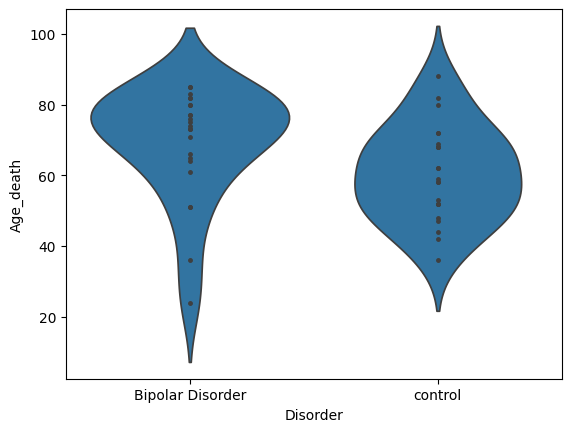

In [22]:
sns.violinplot(adata.obs.groupby(['individualID','Disorder','Biological_Sex']).mean(numeric_only = True), 
               x='Disorder', y="Age_death", #color = "Biological_Sex",
              inner = "point")

In [42]:
adata.obs.groupby(['individualID','Disorder','Biological_Sex']).mean('Age_death').groupby(['Disorder','Biological_Sex']).describe()['Age_death']

count       mean        std   min   25%  \
Disorder         Biological_Sex                                            
Bipolar Disorder female           11.0  72.272727  10.488955  51.0  65.0   
                 male             10.0  69.700000  15.470761  36.0  66.5   
control          female           10.0  61.300000   6.684144  52.0  58.0   
                 male             11.0  60.272727  17.709268  36.0  47.5   

                                  50%    75%   max  
Disorder         Biological_Sex                     
Bipolar Disorder female          76.0  80.00  85.0  
                 male            73.5  80.75  85.0  
control          female          60.5  66.50  72.0  
                 male            52.0  74.00  88.0

In [ ]:
adata.obs['cond_sex'] = adata.obs.Disorder.replace({'control': 'NTC', 'Bipolar Disorder': 'BD'}) + " " + adata.obs.Biological_Sex.replace({'female': 'F', 'male': 'M'})


In [101]:
adata.obs.cond_sex.cat.categories
df["size"] = df["size"].astype("category")

# 2. Reorder the categories logically and set ordered=True
df["size"] = df["size"].cat.reorder_categories(
    ["small", "medium", "large"], ordered=True
)

Index(['BD F', 'BD M', 'NTC F', 'NTC M'], dtype='object')

<Axes: xlabel='cond_sex', ylabel='Age_death'>

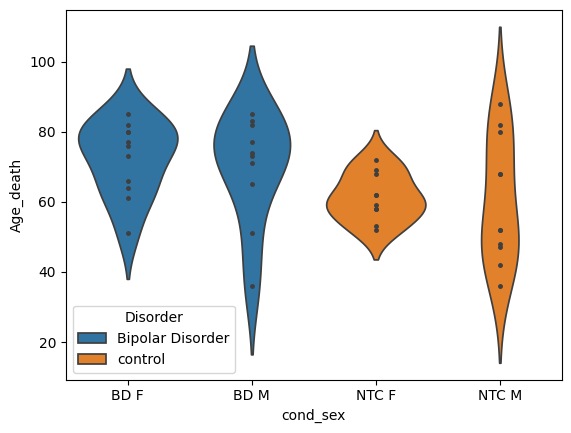

In [46]:
sns.violinplot(adata.obs.groupby(['individualID','cond_sex','Disorder']).mean(numeric_only = True), 
               x='cond_sex', y="Age_death", hue = "Disorder",
              inner = "point")

<Axes: xlabel='ncells', ylabel='Count'>

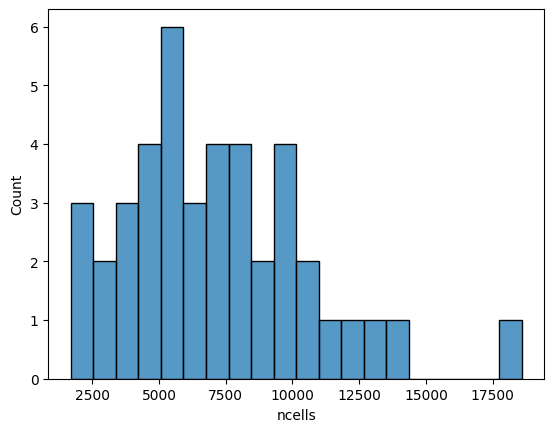

In [47]:
df_tally = adata.obs.groupby(['individualID','Disorder','Biological_Sex'], 
                              observed=True).size().reset_index(name='ncells')
sns.histplot(df_tally, x="ncells", log_scale= True, bins=20)

In [20]:
df_tally.groupby(['Disorder','Biological_Sex']).size()

Disorder          Biological_Sex
Bipolar Disorder  female            11
                  male              12
control           female            11
                  male              12
dtype: int64

In [21]:
df_tally[df_tally.ncells>1500].groupby(['Disorder','Biological_Sex']).size()

Disorder          Biological_Sex
Bipolar Disorder  female            11
                  male              10
control           female            10
                  male              11
dtype: int64

In [22]:
keepDonors = df_tally.individualID[df_tally.ncells>1500]

In [23]:
adata = adata[adata.obs.individualID.isin(keepDonors)].copy()
adata.shape

(301070, 34291)

<Axes: xlabel='ncells', ylabel='Count'>

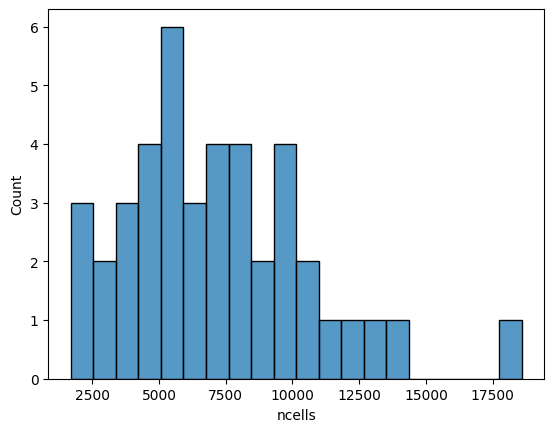

In [33]:
df_tally = adata.obs.groupby(['individualID','Disorder','Biological_Sex'], 
                              observed=True).size().reset_index(name='ncells')
sns.histplot(df_tally, x="ncells", log_scale= False, bins=20)

(0.0, 20000.0)

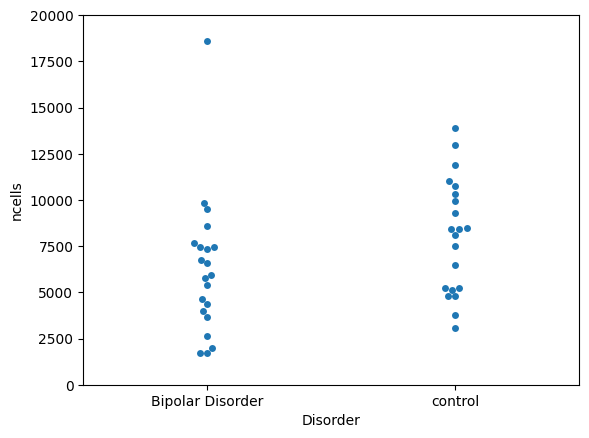

In [54]:
sns.swarmplot(df_tally, x = 'Disorder', y = 'ncells')
plt.ylim(0,20000)

In [55]:
df_tally[df_tally.ncells>18000]

,individualID,Disorder,Biological_Sex,ncells
15,BD4,Bipolar Disorder,female,18585


In [57]:
adata = adata[adata.obs.individualID!="BD4"].copy()
adata.shape

(282485, 34291)

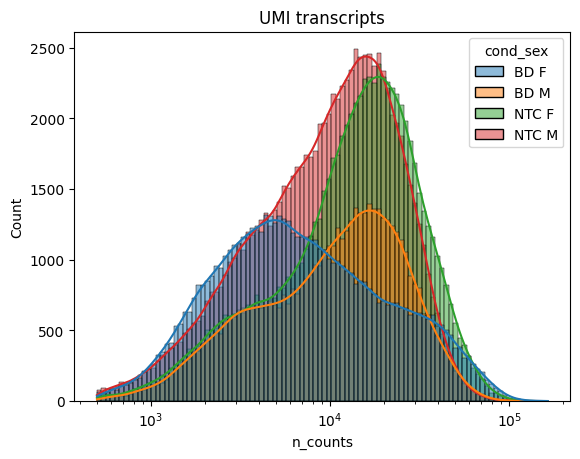

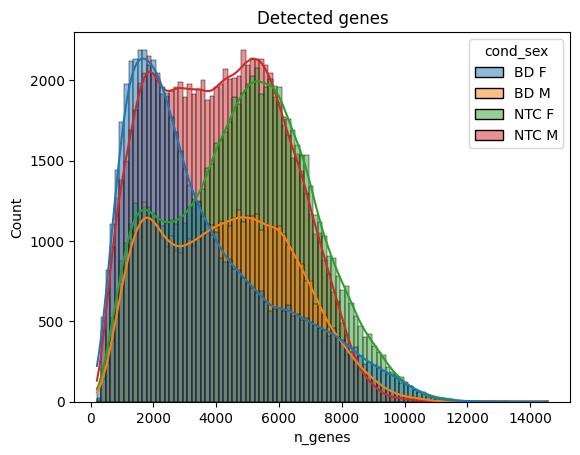

In [58]:
p1 = sns.histplot(adata.obs, x="n_counts", hue="cond_sex", bins=100, kde= True, log_scale = True)
plt.title("UMI transcripts")
plt.show()
p2 = sns.histplot(adata.obs, x="n_genes", hue="cond_sex", bins=100, kde=True)
plt.title("Detected genes")
plt.show()

In [12]:
adata.shape

(303771, 34291)

In [59]:
sc.pp.filter_genes(adata, min_counts=50)
adata.shape

(282485, 31126)

In [60]:
adata

AnnData object with n_obs × n_vars = 282485 × 31126
    obs: 'n_genes', 'n_counts', 'Channel', 'demux_type', 'assignment', 'anno', 'subclass', 'azimuth', 'individualID', 'Biological_Sex', 'Age_death', 'Disorder', 'cond_sex'
    var: 'featureid', 'n_cells', 'percent_cells', 'n_counts'
    uns: 'PCs', '_attr2type', 'genome', 'leiden_resolution', 'modality', 'ncells', 'norm_count', 'pca', 'pca_features', 'stdzn_max_value', 'stdzn_mean', 'stdzn_std', 'uns_dict', 'var_dict', 'cond_sex_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_pca_regressed', 'X_pca_regressed_harmony', 'X_umap', 'pca_harmony_knn_distances', 'pca_harmony_knn_indices', 'pca_regressed_harmony_knn_distances', 'pca_regressed_harmony_knn_indices'
    varm: 'de_res', 'means', 'partial_sum'
    layers: 'counts'
    obsp: 'W_pca_harmony', 'W_pca_regressed_harmony'

In [61]:
# faster version, but I had wanted to check
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)

In [62]:
# preserve logcounts
adata.layers["logcounts"] = adata.X.copy()

In [63]:
adata

AnnData object with n_obs × n_vars = 282485 × 31126
    obs: 'n_genes', 'n_counts', 'Channel', 'demux_type', 'assignment', 'anno', 'subclass', 'azimuth', 'individualID', 'Biological_Sex', 'Age_death', 'Disorder', 'cond_sex'
    var: 'featureid', 'n_cells', 'percent_cells', 'n_counts'
    uns: 'PCs', '_attr2type', 'genome', 'leiden_resolution', 'modality', 'ncells', 'norm_count', 'pca', 'pca_features', 'stdzn_max_value', 'stdzn_mean', 'stdzn_std', 'uns_dict', 'var_dict', 'cond_sex_colors', 'log1p'
    obsm: 'X_pca', 'X_pca_harmony', 'X_pca_regressed', 'X_pca_regressed_harmony', 'X_umap', 'pca_harmony_knn_distances', 'pca_harmony_knn_indices', 'pca_regressed_harmony_knn_distances', 'pca_regressed_harmony_knn_indices'
    varm: 'de_res', 'means', 'partial_sum'
    layers: 'counts', 'logcounts'
    obsp: 'W_pca_harmony', 'W_pca_regressed_harmony'

In [14]:
## this way keeps adata.X as counts, which I don't actually need but was necessary for me to remember how to work with the X assay
#X_norm = sc.pp.normalize_total(adata, target_sum = 1e6, inplace = False)["X"]
#X_norm = sc.pp.log1p(X_norm)
#adata.layers["logcounts"] = X_norm

In [64]:
adata.X.max()

9.012979

/users/jthompso/.conda/envs/snPy/lib/python3.10/site-packages/scanpy/plotting/_utils.py:471: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


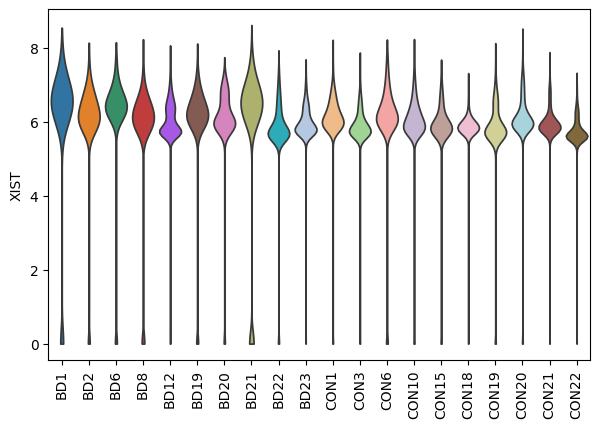

In [65]:
sc.pl.violin(adata[adata.obs.Biological_Sex=="female"], ["XIST"], groupby='individualID', 
             layer = 'logcounts', use_raw = False, 
             size=0, rotation = 90)

/users/jthompso/.conda/envs/snPy/lib/python3.10/site-packages/scanpy/plotting/_utils.py:471: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


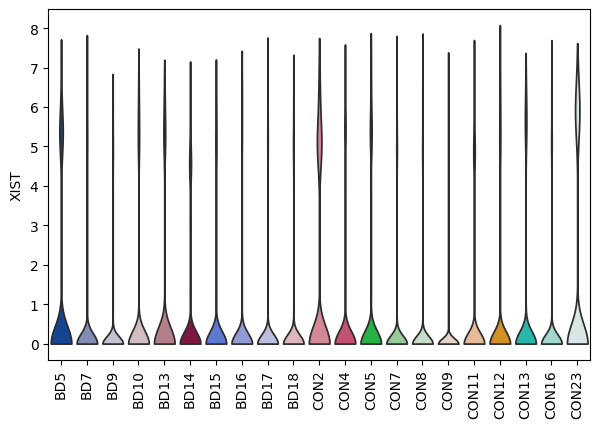

In [66]:
sc.pl.violin(adata[adata.obs.Biological_Sex=="male"], ["XIST"], groupby='individualID', 
             layer = 'logcounts', use_raw = False, 
             size=0, rotation = 90)

/users/jthompso/.conda/envs/snPy/lib/python3.10/site-packages/scanpy/plotting/_utils.py:471: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


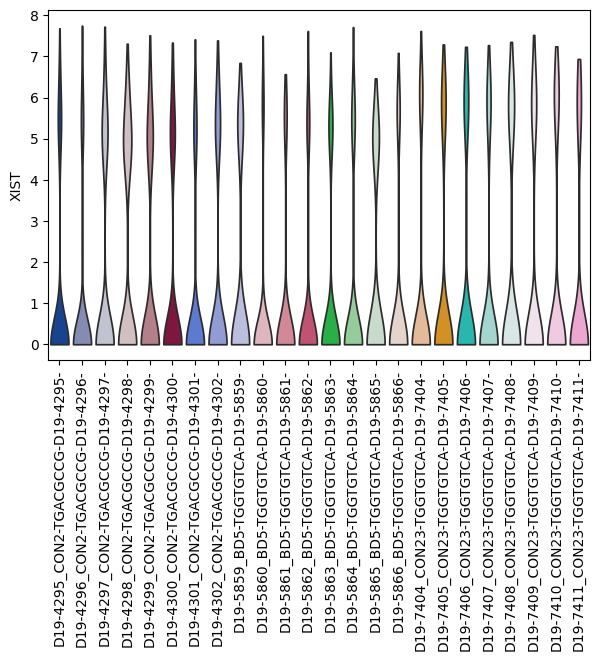

In [158]:
sc.pl.violin(adata[adata.obs.individualID.isin(['BD5','CON2','CON23'])], ["XIST"], groupby='Channel', 
             layer = 'logcounts', use_raw = False, 
             size=0, rotation = 90)

In [114]:
adata.obs[['XIST_lgcounts','DDX3Y_lgcounts','RPS4Y1_lgcounts']] = sc.get.obs_df(adata, keys=['XIST','DDX3Y','RPS4Y1'], layer="logcounts")

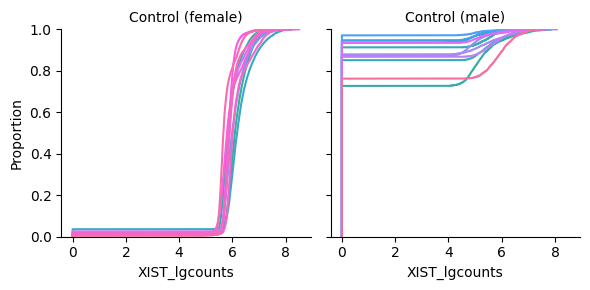

In [138]:
g = sns.FacetGrid(adata.obs[adata.obs.Disorder=="control"], col="Biological_Sex", hue="individualID")
g.map(sns.ecdfplot, 'XIST_lgcounts', log_scale= False)
g.set_titles('Control ({col_name})')

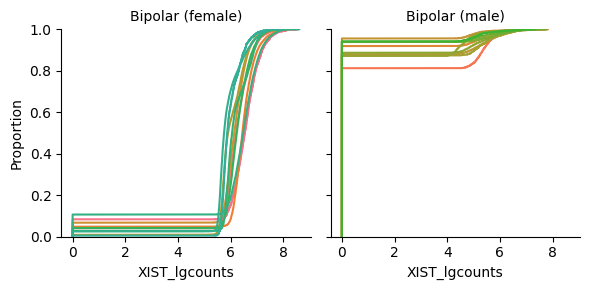

In [139]:
g = sns.FacetGrid(adata.obs[adata.obs.Disorder=="Bipolar Disorder"], col="Biological_Sex", hue="individualID")
g.map(sns.ecdfplot, 'XIST_lgcounts', log_scale= False)
g.set_titles('Bipolar ({col_name})')

In [159]:
#threshold XIST logcounts at 4 or 5
adata.obs['XIST_cutoff'] = adata.obs.XIST_lgcounts >= 4

In [141]:
adata.obs.groupby(['Biological_Sex','XIST_cutoff'], observed = True).size()

Biological_Sex  XIST_cutoff
female          False            4162
                True           135421
male            False          132415
                True            10487
dtype: int64

In [170]:
tmp = adata.obs.groupby(['Biological_Sex','individualID'], observed = True).size().reset_index(name = 'ntotal').copy()

In [181]:
tmp2 = adata.obs.groupby(['Biological_Sex','individualID','XIST_cutoff'], observed = True).size().reset_index(name = 'ncells').copy()

In [182]:
xdf = tmp2[tmp2.XIST_cutoff].merge(tmp)
xdf['prop_XIST'] = xdf.ncells/xdf.ntotal

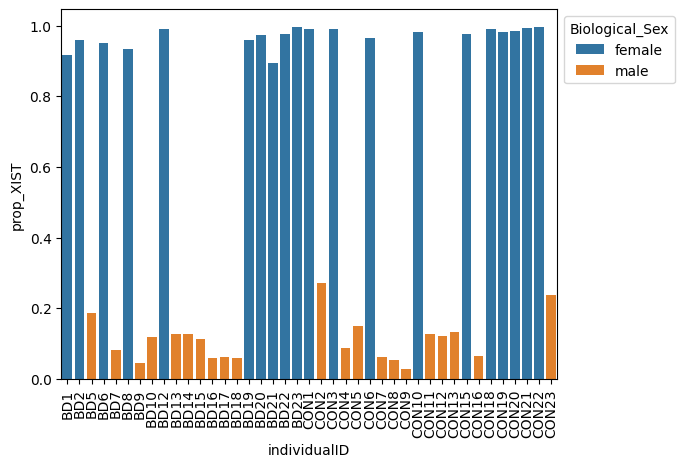

In [183]:
ax = sns.barplot(xdf, x = 'individualID', y = 'prop_XIST', hue = 'Biological_Sex')
plt.xticks(rotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1))
plt.show()

In [165]:
adata.obs.columns

Index(['n_genes', 'n_counts', 'Channel', 'demux_type', 'assignment', 'anno',
       'subclass', 'azimuth', 'individualID', 'Biological_Sex', 'Age_death',
       'Disorder', 'cond_sex', 'XIST_lgcounts', 'DDX3Y_lgcounts',
       'RPS4Y1_lgcounts', 'XIST_cutoff'],
      dtype='object')

In [195]:
adata.obs['eitherY'] = adata.obs.DDX3Y_lgcounts + adata.obs.RPS4Y1_lgcounts

In [166]:
adata.obs['neitherY'] = (adata.obs['DDX3Y_lgcounts'] == 0) & (adata.obs['RPS4Y1_lgcounts'] == 0)

n_genes  n_counts  Age_death  \
Biological_Sex individualID XIST_cutoff                                  
female         BD1          False          145161    269322      10293   
                            True          3252208   7985507     113223   
               BD2          False          160812    289400      11840   
                            True         11297228  34342336     280000   
               BD6          False          538320    987515      25071   
...                                           ...       ...        ...   
male           CON13        True          4790469  13210437      97240   
               CON16        False        29483193  86103887     295386   
                            True          2145149   6415277      20706   
               CON23        False         7239986  19972793     138048   
                            True          2456090   7157501      43104   

                                         XIST_lgcounts  DDX3Y_lgcounts  \
Biological_Sex individualID XIST_cutoff                                  
female         BD1          False             0.000000        0.000000   
                            True          10272.625977       66.919846   
               BD2          False             0.000000        0.000000   
                            True          22051.964844      277.770782   
               BD6          False             0.000000      179.597076   
...                                                ...             ...   
male           CON13        True           8232.332031     1720.857910   
               CON16        False             0.000000    10140.135742   
                            True           2700.411133      682.737000   
               CON23        False             0.000000     2061.566895   
                            True           5344.971191      661.045837   

                                         RPS4Y1_lgcounts  neitherY  
Biological_Sex individualID XIST_cutoff                             
female         BD1          False               0.000000       141  
                            True               41.460663      1533  
               BD2          False               0.000000       148  
                            True              171.855408      3420  
               BD6          False              78.983185       372  
...                                                  ...       ...  
male           CON13        True             1534.105591       912  
               CON16        False           12138.360352      3593  
                            True              865.514954       254  
               CON23        False            1620.586060      2285  
                            True              580.003723       696  

[82 rows x 7 columns]

In [176]:
tmp3 = adata.obs.groupby(['Biological_Sex','individualID','XIST_cutoff'], observed = True)['neitherY'].sum().reset_index(name = 'neitherY')

In [184]:
tmp3

,Biological_Sex,individualID,XIST_cutoff,neitherY
0,female,BD1,False,141
1,female,BD1,True,1533
2,female,BD2,False,148
3,female,BD2,True,3420
4,female,BD6,False,372
...,...,...,...,...
77,male,CON13,True,912
78,male,CON16,False,3593
79,male,CON16,True,254
80,male,CON23,False,2285


In [186]:
ydf = tmp3.merge(tmp2)
ydf['prop_nY'] = ydf.neitherY/ydf.ncells

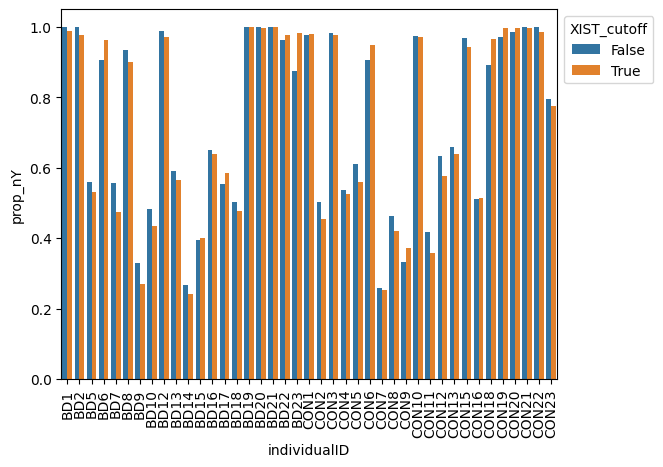

In [187]:
ax = sns.barplot(ydf, x = 'individualID', y = 'prop_nY', hue = 'XIST_cutoff')
plt.xticks(rotation = 90)
sns.move_legend(ax, "upper left", bbox_to_anchor = (1,1))
plt.show()

/users/jthompso/.conda/envs/snPy/lib/python3.10/site-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


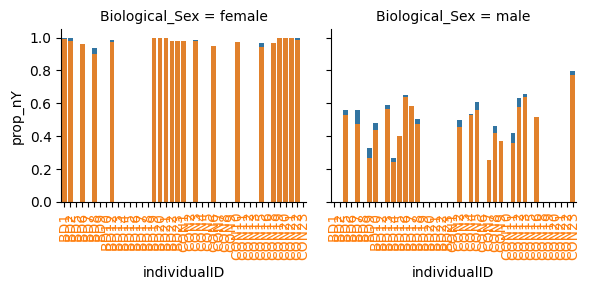

In [194]:
g = sns.FacetGrid(ydf, col = "Biological_Sex", hue="XIST_cutoff", sharex = False)
g.map(sns.barplot, 'individualID', 'prop_nY')
g.map(plt.xticks, rotation = 90)
plt.show()

In [83]:
dxgroups = adata.obs['cond_sex'].cat.categories

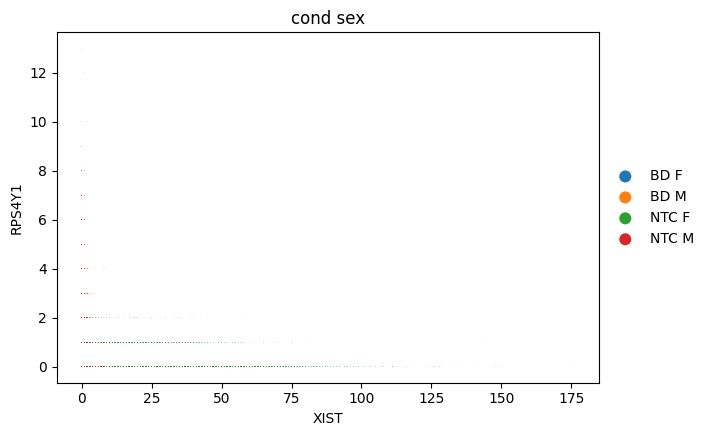

In [98]:
sc.pl.scatter(adata, x = "XIST", y = "RPS4Y1",
                  #use_raw = False, layers = 'logcounts',
                  color='cond_sex')

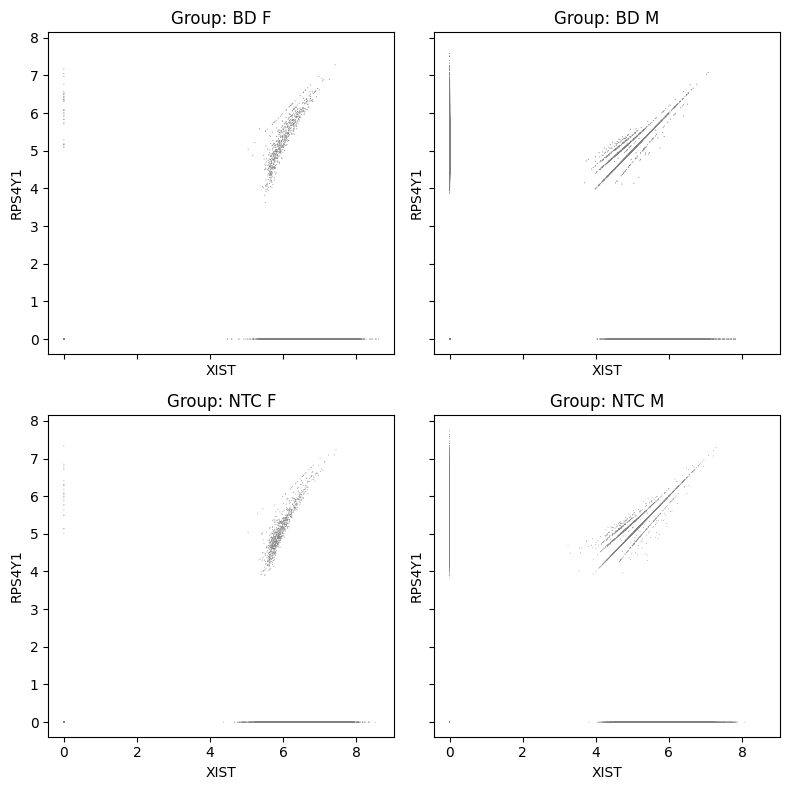

In [112]:
fig, axes = plt.subplots(
    2, 2, figsize=(8, 8), sharex = True, sharey = True
)
axes_flat = axes.flatten()
#set na color to transparent instead of light grey
for i, cat in enumerate(dxgroups):
    sc.pl.scatter(adata[adata.obs.cond_sex== cat ], x = "XIST", y = "RPS4Y1", title= f'Group: {cat}',
                  use_raw = False, layers = 'logcounts',
                  #color='cond_sex', groups=[cat], 
                  ax=axes_flat[i],
                  show=False, legend_loc = 'none')

plt.tight_layout()
plt.show()

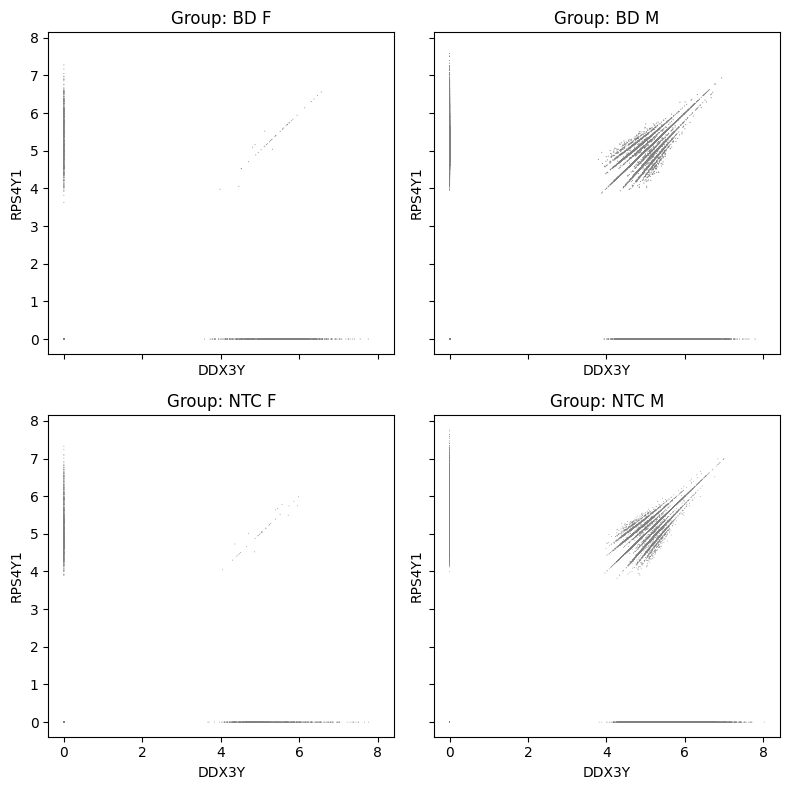

In [113]:
fig, axes = plt.subplots(
    2, 2, figsize=(8, 8), sharex = True, sharey = True
)
axes_flat = axes.flatten()
for i, cat in enumerate(dxgroups):
    sc.pl.scatter(adata[adata.obs.cond_sex== cat ], x = "DDX3Y", y = "RPS4Y1", title= f'Group: {cat}',
                  use_raw = False, layers = 'logcounts',
                  #color='cond_sex', groups=[cat], 
                  ax=axes_flat[i],
                  show=False, legend_loc = 'none')

plt.tight_layout()
plt.show()

In [111]:
adata.var[adata.var.index.isin(['RPS4Y1','RPS4Y2','DDX3Y'])]

,featureid,n_cells,percent_cells,n_counts
featurekey,,,,
RPS4Y1,ENSG00000129824,78983,15.955033,104752.210938
DDX3Y,ENSG00000067048,93268,18.840688,123413.937500
RPS4Y2,ENSG00000280969,16,0.003232,19.313005


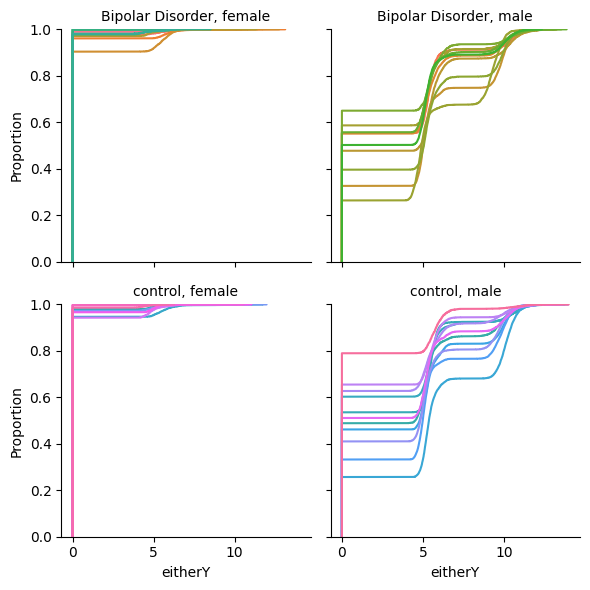

In [201]:
g = sns.FacetGrid(adata.obs, col="Biological_Sex", row = "Disorder", hue="individualID")
g.map(sns.ecdfplot, 'eitherY', log_scale= False)
g.set_titles('{row_name}, {col_name}')
plt.show()

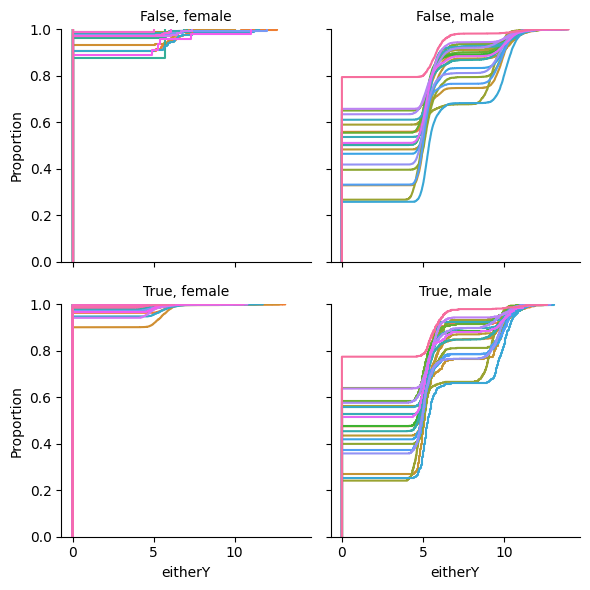

In [202]:
g = sns.FacetGrid(adata.obs, col="Biological_Sex", row = "XIST_cutoff", hue="individualID")
g.map(sns.ecdfplot, 'eitherY', log_scale= False)
g.set_titles('{row_name}, {col_name}')
plt.show()

In [ ]:
# honestly none of this looks that bad? only CON23 is a little suspect but these don't look like those pseudobulk plots at all?

In [203]:
adata.obs[['XIST_counts','DDX3Y_counts','RPS4Y1_counts']] = sc.get.obs_df(adata, keys=['XIST','DDX3Y','RPS4Y1'], layer="counts")

In [208]:
out1 = adata.obs.groupby(['individualID','Disorder','Biological_Sex'], observed = True)[['XIST_counts','DDX3Y_counts','RPS4Y1_counts']].sum()
out2 = adata.obs.groupby(['individualID','Disorder','Biological_Sex'], observed = True).size().reset_index(name = 'ncells')

In [215]:
out2.merge(out1.reset_index()).to_csv("/dcs04/lieber/marmaypag/spatialDLPFC_mdd_bpd_LIBD4100/spatialDLPFC_mdd_bpd/processed-data/08_compare_DEGs/SZBDMulti-seq/check_sex-chrM_raw-counts.csv")